# Beta diversity of the ITS fungal community

**Question.** Does fungal community composition differ among **plant genera**, between **sampling times**, and does the effect of time **depend on the genus** (interaction)?

**Design.** 18 independent samples (each from a different soil): 3 plant genera × 2 times × 3 replicates.

| Factor | Levels | Taken from the sample name |
|---|---|---|
| `plant_genus` | E, T, R | 1st letter |
| `Time` | B, F | 2nd letter |
| replicate | 1, 2, 3 | 3rd character |

*Example: sample `EF1` = genus **E**, time **F**, replicate **1**.*

**Workflow**

1. Load libraries and set seed
2. Load ASV counts and taxonomy into a `phyloseq` object
3. Collapse ASVs to genus and convert to relative abundance
4. Bray-Curtis distances → two-way **PERMANOVA** (genus × time)
5. **PERMDISP**: are the groups equally spread?
6. **Post hoc** (exploratory)
7. Reading test results
8. Extra plots (thesis)

---
## 1. Setup

The packages used throughout this notebook are loaded below. phyloseq is installed from Bioconductor, vegan, openxlsx, ggplot2, dplyr, ggdendro, tibble and UpSetR are available from CRAN, and pairwiseAdonis is installed from GitHub. set.seed() ensures that permutation tests are reproducible.

Bioconductor:

BiocManager::install("phyloseq")

CRAN:

install.packages(c("vegan", "openxlsx", "ggplot2", "dplyr", "ggdendro", "tibble", "UpSetR"))

GitHub:

remotes::install_github("pmartinezarbizu/pairwiseAdonis/pairwiseAdonis")

In [1]:
library(phyloseq)
library(vegan)
library(openxlsx)
library(ggplot2)
library(dplyr)
library(ggdendro)
library(tibble)
library(UpSetR)
library(pairwiseAdonis)

set.seed(125)

Loading required package: permute


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: cluster



---
## 2. Load the data

The Excel file has two sheets of intrest: the **ASV count table** and the **taxonomy** of each ASV. Sample metadata (genus and time) is read from the sample names here.

> The `stopifnot()` line stops the notebook if any ASV is missing from the taxonomy table.

In [2]:
asv <- read.xlsx("datasets/ITS_table_200.xlsx", sheet = "ITS-table", rowNames = TRUE)
asv[] <- lapply(asv, as.numeric)

tax <- read.xlsx("datasets/ITS_table_200.xlsx", sheet = "taxonomy", rowNames = TRUE)
colnames(tax) <- c("Kingdom", "Phylum", "Class", "Order", "Family", "Genus", "Species", "Strain")
stopifnot(all(rownames(asv) %in% rownames(tax)))

ps <- phyloseq(otu_table(asv, taxa_are_rows = TRUE), tax_table(as.matrix(tax)))

sample_data(ps) <- data.frame(
  plant_genus = factor(substr(sample_names(ps), 1, 1), levels = c("E", "T", "R")),
  Time        = factor(substr(sample_names(ps), 2, 2), levels = c("B", "F")),
  row.names   = sample_names(ps))
ps

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 7275 taxa and 18 samples ]
sample_data() Sample Data:       [ 18 samples by 2 sample variables ]
tax_table()   Taxonomy Table:    [ 7275 taxa by 8 taxonomic ranks ]

---
## 3. Genus level and relative abundance

- `tax_glom()` sums all ASVs that belong to the same genus.
- `NArm = FALSE` **Keeps ASVs with no genus assignment**, so relative abundances are calculated on the collapsed genus-assigned reads and uncolassed higher taxonomical order reads avoiding leakage.
- Converting to relative abundance removes differences in sequencing depth between samples before computing Bray-Curtis wich is a library size sensitive metric.

In [3]:
ps     <- tax_glom(ps, taxrank = "Genus", NArm = FALSE)
ps_rel <- transform_sample_counts(ps, \(x) x / sum(x))
ps_rel

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 163 taxa and 18 samples ]
sample_data() Sample Data:       [ 18 samples by 2 sample variables ]
tax_table()   Taxonomy Table:    [ 163 taxa by 8 taxonomic ranks ]

---
## 4. PERMANOVA: Bray-Curtis ~ genus × time

**Bray-Curtis** measures how different two samples are. **PERMANOVA** splits the total variation among samples into *genus*, *time*, their *interaction* and *residual*, and tests each part with 9,999 permutations.

> **Balanced design check.** The table of replicates below should show 3 samples in every cell. PERMANOVA should be robust to unequal group spread only when the design is balanced.
> **Interaction.** If `plant_genus:Time` is significant, the effect of time might differ among genera, so the main effects should not be interpreted on their own. That is what the post hoc in section 6 is for.

In [4]:
bray <- phyloseq::distance(ps_rel, method = "bray")
meta <- data.frame(sample_data(ps_rel))

table(meta$plant_genus, meta$Time)    # replicates per group

perm_test <- adonis2(bray ~ plant_genus * Time, data = meta, permutations = 9999, by = "terms")
perm_test

   
    B F
  E 3 3
  T 3 3
  R 3 3

,Df,SumOfSqs,R2,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
plant_genus,2,1.3104591,0.4599997,20.842224,1e-04
Time,1,0.5552633,0.1949095,17.662394,1e-04
plant_genus:Time,2,0.6058526,0.2126675,9.635795,1e-04
Residual,12,0.3772512,0.1324234,NA,NA
Total,17,2.8488264,1.0000000,NA,NA


---
## 5. PERMDISP: are the six groups equally spread?

PERMANOVA reacts to differences in **location** (group centroid) **and** in **dispersion** (spread around the group centroid). PERMDISP tests whether the six genus × time groups differ in dispersion. `betadisper()` performs a PCoA of the Bray-Curtis distance matrix and calculates the distance of each sample to its group centroid. `permutest()` then uses permutations to test whether these distances differ among groups.

Notes:
- With a **balanced** design, PERMANOVA is largely unaffected by unequal dispersion (Anderson & Walsh 2013).

- With only 3 samples per group, PERMDISP has **little power**: a non-significant result is weak evidence of homogeneity.

- `bias.adjust = TRUE` corrects the small-sample bias in the distances.

- The plot shows the 3 individual points per group, and the printed values are the dispersion test results and the mean dispersion per group.




Permutation test for homogeneity of multivariate dispersions
Permutation: free
Number of permutations: 9999

Response: Distances
          Df   Sum Sq   Mean Sq      F N.Perm Pr(>F)
Groups     5 0.017251 0.0034502 0.6224   9999 0.6908
Residuals 12 0.066525 0.0055437                     

E.B   T.B   R.B   E.F   T.F   R.F 
0.147 0.153 0.178 0.132 0.229 0.166

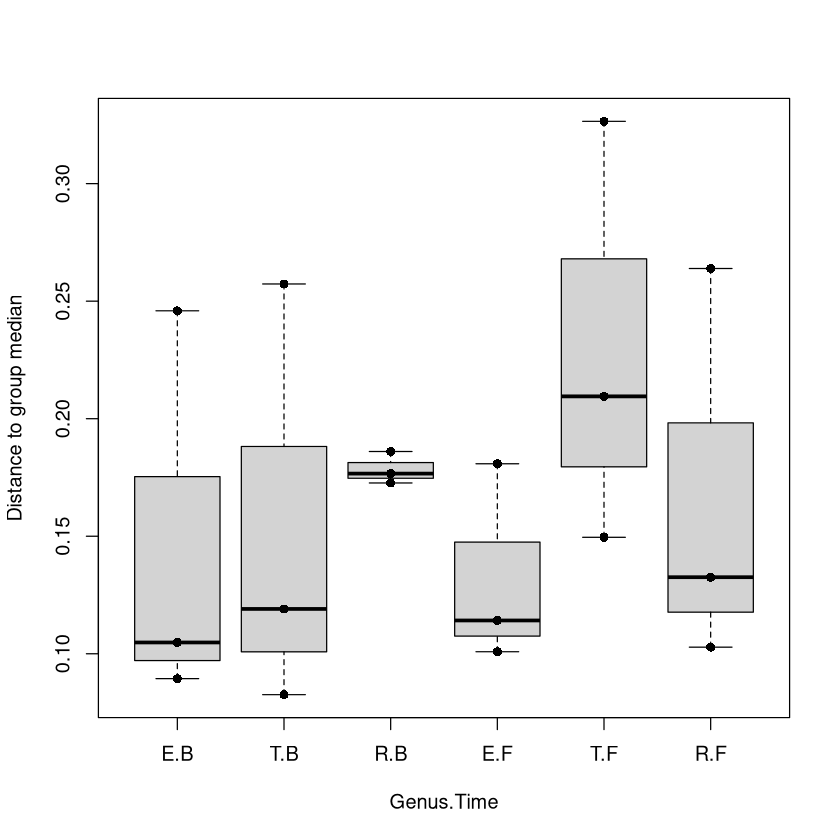

In [5]:
groups    <- interaction(meta$plant_genus, meta$Time)
disp      <- betadisper(bray, groups, bias.adjust = TRUE)

#PERMDISP
disp_test <- permutest(disp, permutations = 9999)
disp_test

round(tapply(disp$distances, groups, mean), 3)             # mean dispersion per group

boxplot(disp, ylab = "Distance to group median", xlab = "Genus.Time")
stripchart(disp$distances ~ groups, vertical = TRUE, add = TRUE, pch = 16)

---
## 6. Post hoc (exploratory): one factor within levels of the other

Because the interaction was significant, we compared one factor within each level of the other as implemented in PERMANOVA+ (Anderson et al. 2008). To contextualize pairwise shifts within the broader dataset, we evaluated pairwise effect sizes relative to the full 18-sample model:

1. **Filtered pairwise pairs (`pairwiseAdonis`):** Kept the 9 pairs differing in only one factor to extract their pairwise Sums of Squares (`SumsOfSqs`).
2. **Re-scaled against full model:**
* **`R2_total`** (`SS / Total_SS`): Proportion of **total experiment variance** explained by the comparison.
* **`F_pooled`** (`SS / Residual_MS`): An *F*-statistic using the full model's residual error (12 df) to retain sensitivity.


> **Limitation.** With *n* = 3 per group, pairwise *p*-values cannot drop below 0.1. These metrics are strictly exploratory and descriptive, assuming roughly equal multivariate dispersion across groups.

In [6]:
# all 15 pairwise PERMANOVAs between the 6 genus x time groups
ph <- suppressMessages(pairwise.adonis(bray, groups, perm = 9999))

# keep only pairs that differ in ONE factor (same genus or same time)
id <- do.call(rbind, strsplit(ph$pairs, " vs |\\."))
ph <- ph[id[, 1] == id[, 3] | id[, 2] == id[, 4], ]

print(ph)


#Isolate variations of the full model
res <- perm_test["Residual", ]
ph$R2_total <- ph$SumsOfSqs / perm_test["Total", "SumOfSqs"]
ph$F_pooled <- ph$SumsOfSqs / (res$SumOfSqs / res$Df)
print(ph[, c("pairs", "SumsOfSqs", "R2_total", "F_pooled")], digits = 3)

        pairs Df SumsOfSqs   F.Model        R2 p.value p.adjusted sig
1  E.F vs E.B  1 0.3005325 13.772441 0.7749324     0.1          1    
2  E.F vs T.F  1 0.3445734  9.284226 0.6988910     0.1          1    
4  E.F vs R.F  1 0.6816263 27.116107 0.8714492     0.1          1    
7  E.B vs T.B  1 0.3883502 15.165736 0.7912942     0.1          1    
9  E.B vs R.B  1 0.4380929 15.493531 0.7948037     0.1          1    
10 T.F vs T.B  1 0.5860548 14.329097 0.7817678     0.1          1    
11 T.F vs R.F  1 0.5997710 13.859263 0.7760266     0.1          1    
14 T.B vs R.B  1 0.4220539 14.446137 0.7831524     0.1          1    
15 R.F vs R.B  1 0.2745286  8.689848 0.6847874     0.1          1    
        pairs SumsOfSqs R2_total F_pooled
1  E.F vs E.B     0.301   0.1055     9.56
2  E.F vs T.F     0.345   0.1210    10.96
4  E.F vs R.F     0.682   0.2393    21.68
7  E.B vs T.B     0.388   0.1363    12.35
9  E.B vs R.B     0.438   0.1538    13.94
10 T.F vs T.B     0.586   0.2057    18.64
11 T.F

---
## 7. Reading the results

### Omnibus tests and variance partition

* Genus explains the most variation (`R2` ≈ 0.46), then the genus × time interaction (≈ 0.21) and time (≈ 0.19). Only ≈ 0.13 is residual. All terms have *p* = 1e-4, the minimum for 9,999 permutations.
* PERMDISP was not significant (*p* = 0.69). Mean dispersion was similar across groups (0.13 to 0.23, highest in T.F). With 3 samples per group the test has little power, so this is an absence of evidence of unequal spread, not proof of homogeneity. The balanced design also protects PERMANOVA against unequal spread (Anderson & Walsh 2013) so, in theory, differences should be mostly attributed to centroid changes despite low replicate number.

### How the post hoc was done, and its limits

* Because the interaction is significant, one factor is compared within the levels of the other (Anderson et al. 2008): Time within each genus, and genus within each time.
* Traditional subsetted pairwise tests severely lack statistical power here. Two groups of 3 have only 10 distinct permutations, meaning the lowest possible exact *p*-value is 0.1.
* Because of these limitations, the goal is not to try reaching non-existent significance, but rather to extract meaningful effect sizes from the full model to be more informed.
* We isolated the specific Sums of Squares for each direct pair. We then calculated exploratory `F` and `R2` metrics by pooling the residual error from the full model (12 df).

### Time within each genus

| Comparison | Sum of Squares | `R2` of total variation | `F` (1, 12 df) |
| --- | --- | --- | --- |
| **E**: F vs B | 0.301 | 0.106 | 9.56 |
| **T**: F vs B | 0.586 | 0.206 | 18.64 |
| **R**: F vs B | 0.275 | 0.096 | 8.73 |

* A Time effect is present in all three genera, but Genus **T** shifts roughly 2× more than E or R in absolute terms (SS = 0.586 vs 0.301 and 0.275).
* The three `R2` values (totaling ~0.408) account for the combined Time + Interaction variation seen in the full omnibus model (this happens because Time has 1 degree of freedom).

### Genus within each time

| Time | Comparison | Sum of Squares | `R2` of total variation | `F` (1, 12 df) |
| --- | --- | --- | --- | --- |
| **B** | E vs T | 0.388 | 0.136 | 12.36 |
| **B** | E vs R | 0.438 | 0.154 | 13.94 |
| **B** | T vs R | 0.422 | 0.148 | 13.43 |
| **F** | E vs T | 0.345 | 0.121 | 10.96 |
| **F** | E vs R | 0.682 | 0.239 | 21.69 |
| **F** | T vs R | 0.600 | 0.211 | 19.08 |

* Extracting the exact pairwise effect sizes makes the root of the interaction clearer.
* **At time B:** All three genera are roughly equidistant from one another. The differences between E–T, E–R, and T–R are very similar in size (SS ranging from 0.388 to 0.438).
* **At time F:** The community structures diverge asymmetrically. The distance between E and T decreases slightly (SS = 0.345), but R pulls away significantly from both E (SS = 0.682, roughly 1.5× higher than at time B) and T (SS = 0.600, roughly 1.4× higher than at time B).
* **Note on R2 additivity:** Unlike the "Time within each genus" comparisons, the `R2` values here cannot be summed to match the omnibus model terms. Because Genus has 3 levels (2 degrees of freedom), making 3 pairwise comparisons extracts overlapping variances. These `R2` values should therefore be interpreted as global effect sizes that map the geometric distortion of the groups, rather than additive fractions of a whole.


---
## 8. Extra plots

The following plots provide visual support for the numerical results and represent the figures intended for inclusion in the thesis.


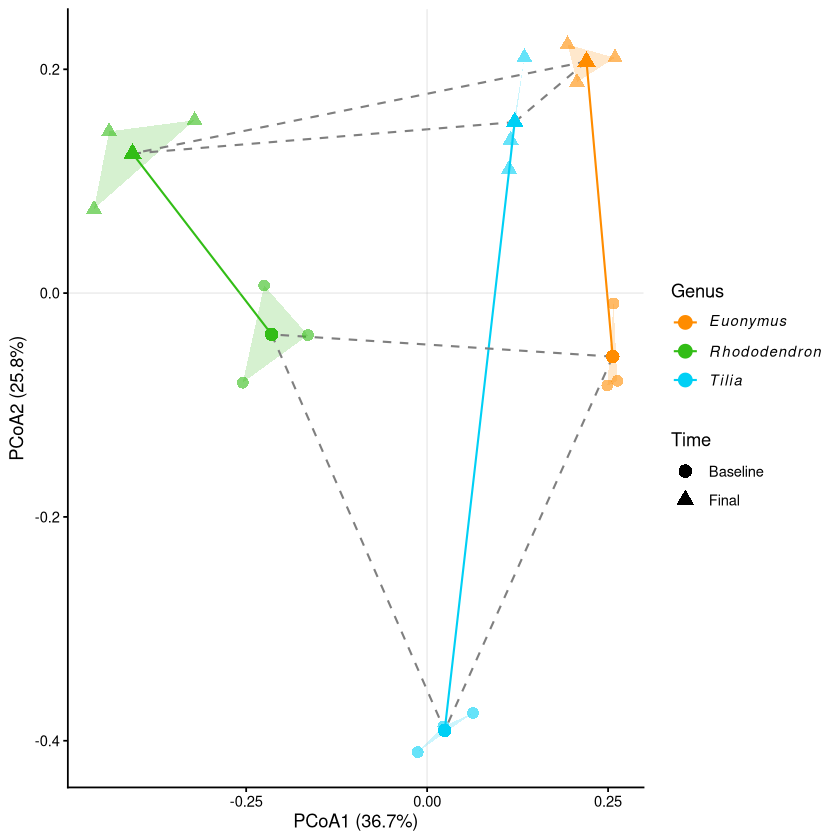

In [7]:
PCOA_X <- data.frame(
  PCoA1 = disp$vectors[, 1],
  PCoA2 = disp$vectors[, 2],
  Genus = sub("\\..*", "", disp$group), # Extracts E, T, R
  Time  = sub(".*\\.", "", disp$group))  # Extracts B, F


hulls <- PCOA_X %>%
  group_by(Genus, Time) %>%
  slice(chull(PCoA1, PCoA2))

centroids <- PCOA_X %>%
  group_by(Genus, Time) %>%
  summarise(
    PCoA1 = mean(PCoA1),
    PCoA2 = mean(PCoA2),
    .groups = "drop")

centroid_lines <- centroids %>%
  tidyr::pivot_wider(
    names_from = Time,
    values_from = c(PCoA1, PCoA2))

centroid_connections <- merge(centroids, centroids, by = "Time") %>%
  filter(Genus.x < Genus.y)


ggplot(PCOA_X, aes(x = PCoA1, y = PCoA2, color = Genus, shape = Time)) +
geom_polygon( data = hulls, aes(fill = Genus, group = interaction(Genus, Time)), alpha = 0.2, color = NA) +
geom_segment(data = centroid_lines,
  aes(x = PCoA1_B, y = PCoA2_B, xend = PCoA1_F, yend = PCoA2_F, color = Genus),
  linewidth = 0.6,
  inherit.aes = FALSE) +
geom_segment(data = centroid_connections,
  aes(x = PCoA1.x, y = PCoA2.x, xend = PCoA1.y, yend = PCoA2.y),
  color = "grey50",
  linetype = "dashed",
  linewidth = 0.6,
  inherit.aes = FALSE) +
geom_point(size = 3, alpha = 0.6) +
geom_point(data = centroids, size = 3.5) +
scale_color_manual(values = c("E" = "#FF8C00", "R" = "#32bd16", "T" = "#00d0f5"),
    labels = c("E" = expression(italic(Euonymus)), "R" = expression(italic(Rhododendron)), "T" = expression(italic(Tilia)))) +
scale_fill_manual(values = c("E" = "#FF8C00", "R" = "#32bd16", "T" = "#00d0f5"), guide = "none") +
scale_shape_manual(values = c("B" = 16, "F" = 17), labels = c("B" = "Baseline", "F" = "Final")) +
theme_classic()+
geom_hline(yintercept = 0, color = "grey70", alpha=0.2) +
geom_vline(xintercept = 0, color = "grey70", alpha=0.2) +
labs( x = paste0("PCoA1 (", round(disp$eig[1] / sum(disp$eig) * 100, 1), "%)"),
      y = paste0("PCoA2 (", round(disp$eig[2] / sum(disp$eig) * 100, 1), "%)") )

Run 0 stress 0.1019237 
Run 1 stress 0.1019237 
... New best solution
... Procrustes: rmse 1.986228e-05  max resid 6.112193e-05 
... Similar to previous best
Run 2 stress 0.1019237 
... Procrustes: rmse 1.858292e-05  max resid 5.670176e-05 
... Similar to previous best
Run 3 stress 0.1019237 
... New best solution
... Procrustes: rmse 1.165645e-06  max resid 3.232198e-06 
... Similar to previous best
Run 4 stress 0.1019237 
... Procrustes: rmse 7.34234e-06  max resid 2.466479e-05 
... Similar to previous best
Run 5 stress 0.1019237 
... New best solution
... Procrustes: rmse 2.723663e-06  max resid 9.949454e-06 
... Similar to previous best
Run 6 stress 0.1019237 
... Procrustes: rmse 5.221143e-06  max resid 1.586911e-05 
... Similar to previous best
Run 7 stress 0.1019237 
... Procrustes: rmse 3.668791e-05  max resid 0.0001223513 
... Similar to previous best
Run 8 stress 0.1019237 
... Procrustes: rmse 1.609973e-05  max resid 5.265943e-05 
... Similar to previous best
Run 9 stress 0.

[1] 0.1019237

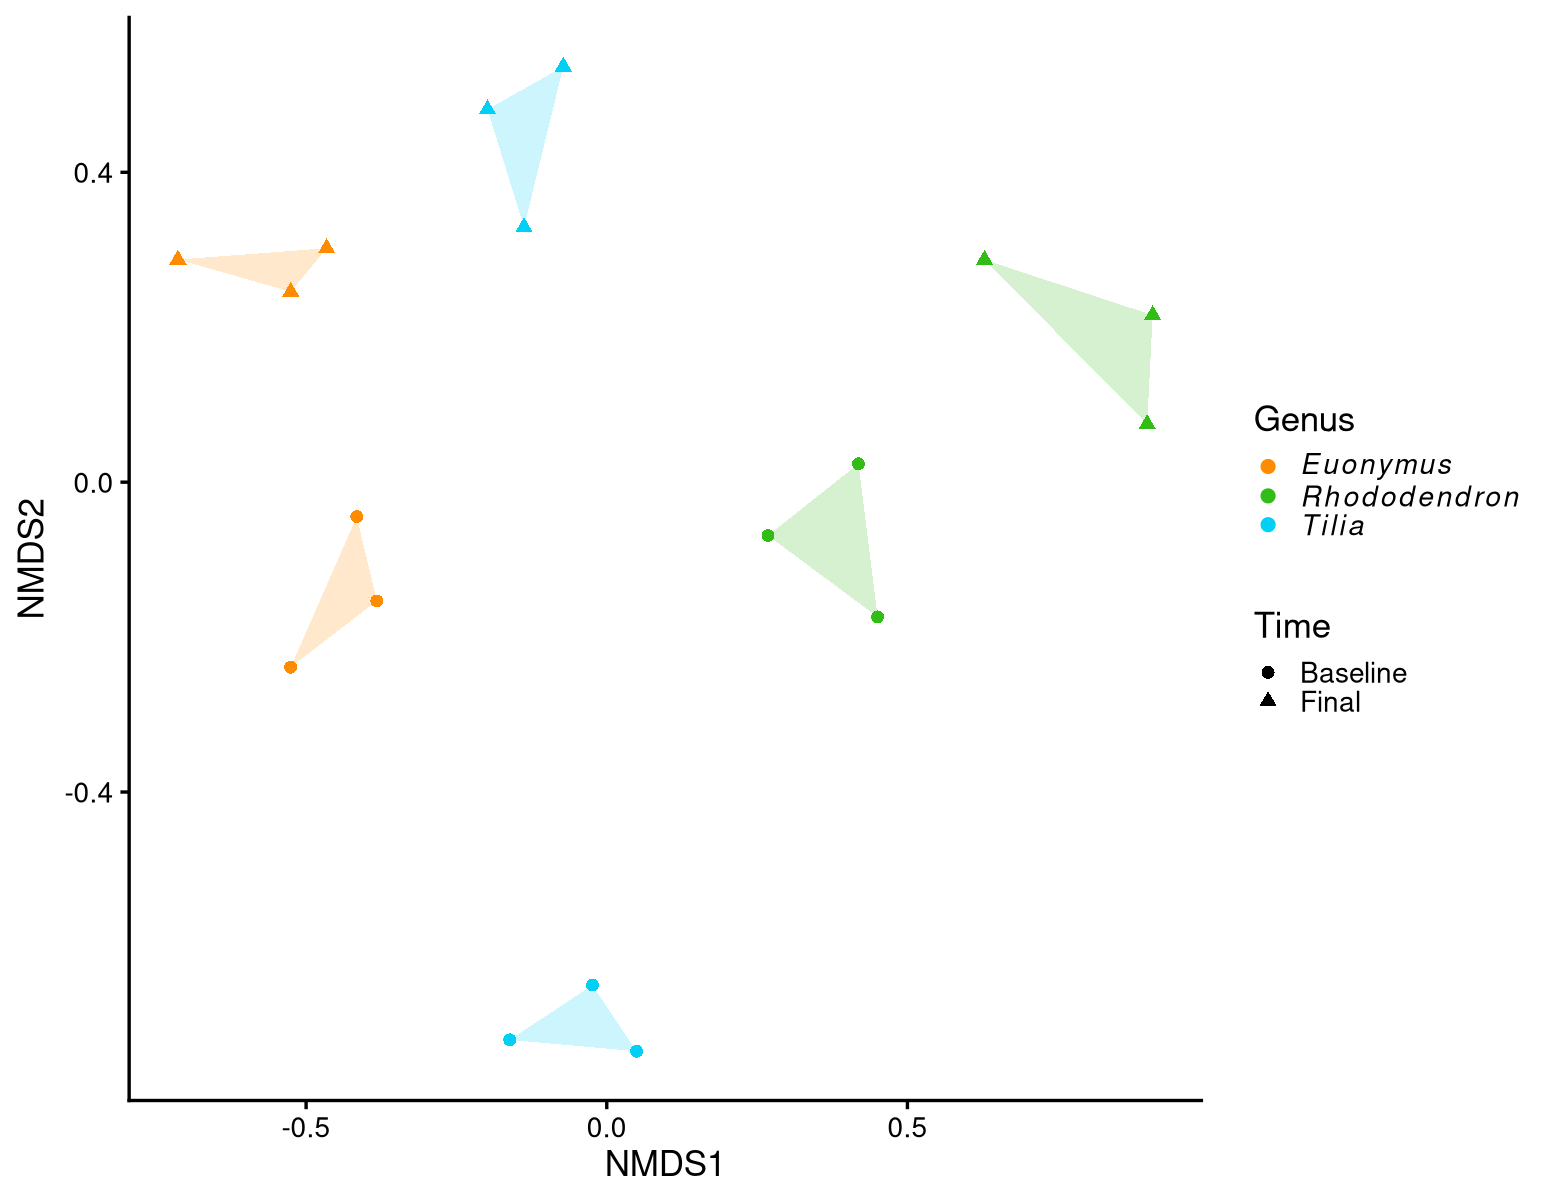

In [8]:
options(repr.plot.width = 13, repr.plot.height = 10)
nmds <- metaMDS(bray, k = 2, trymax = 100)

NMDS_X <- data.frame(
  NMDS1 = nmds$points[, 1],
  NMDS2 = nmds$points[, 2],
  Genus = sub("\\..*", "", disp$group), # Extracts E, T, R
  Time  = sub(".*\\.", "", disp$group))  # Extracts B, F

hulls <- NMDS_X %>%
  group_by(Genus, Time) %>%
  slice(chull(NMDS1, NMDS2))

ggplot(NMDS_X, aes(x = NMDS1, y = NMDS2, color = Genus, shape = Time)) +
geom_polygon(data = hulls, aes(fill = Genus, group = interaction(Genus, Time)), alpha = 0.2, color = NA) +
geom_point(size = 3) +
scale_color_manual(values = c("E" = "#FF8C00", "R" = "#32bd16", "T" = "#00d0f5"),
    labels = c("E" = expression(italic(Euonymus)), "R" = expression(italic(Rhododendron)), "T" = expression(italic(Tilia)))) +
scale_fill_manual(values = c("E" = "#FF8C00", "R" = "#32bd16", "T" = "#00d0f5"), guide = "none") +
scale_shape_manual(values = c("B" = 16, "F" = 17),
    labels = c("B" = "Baseline", "F" = "Final")) +
theme_classic(base_size=21) +
labs(x = "NMDS1", y = "NMDS2")


nmds$stress

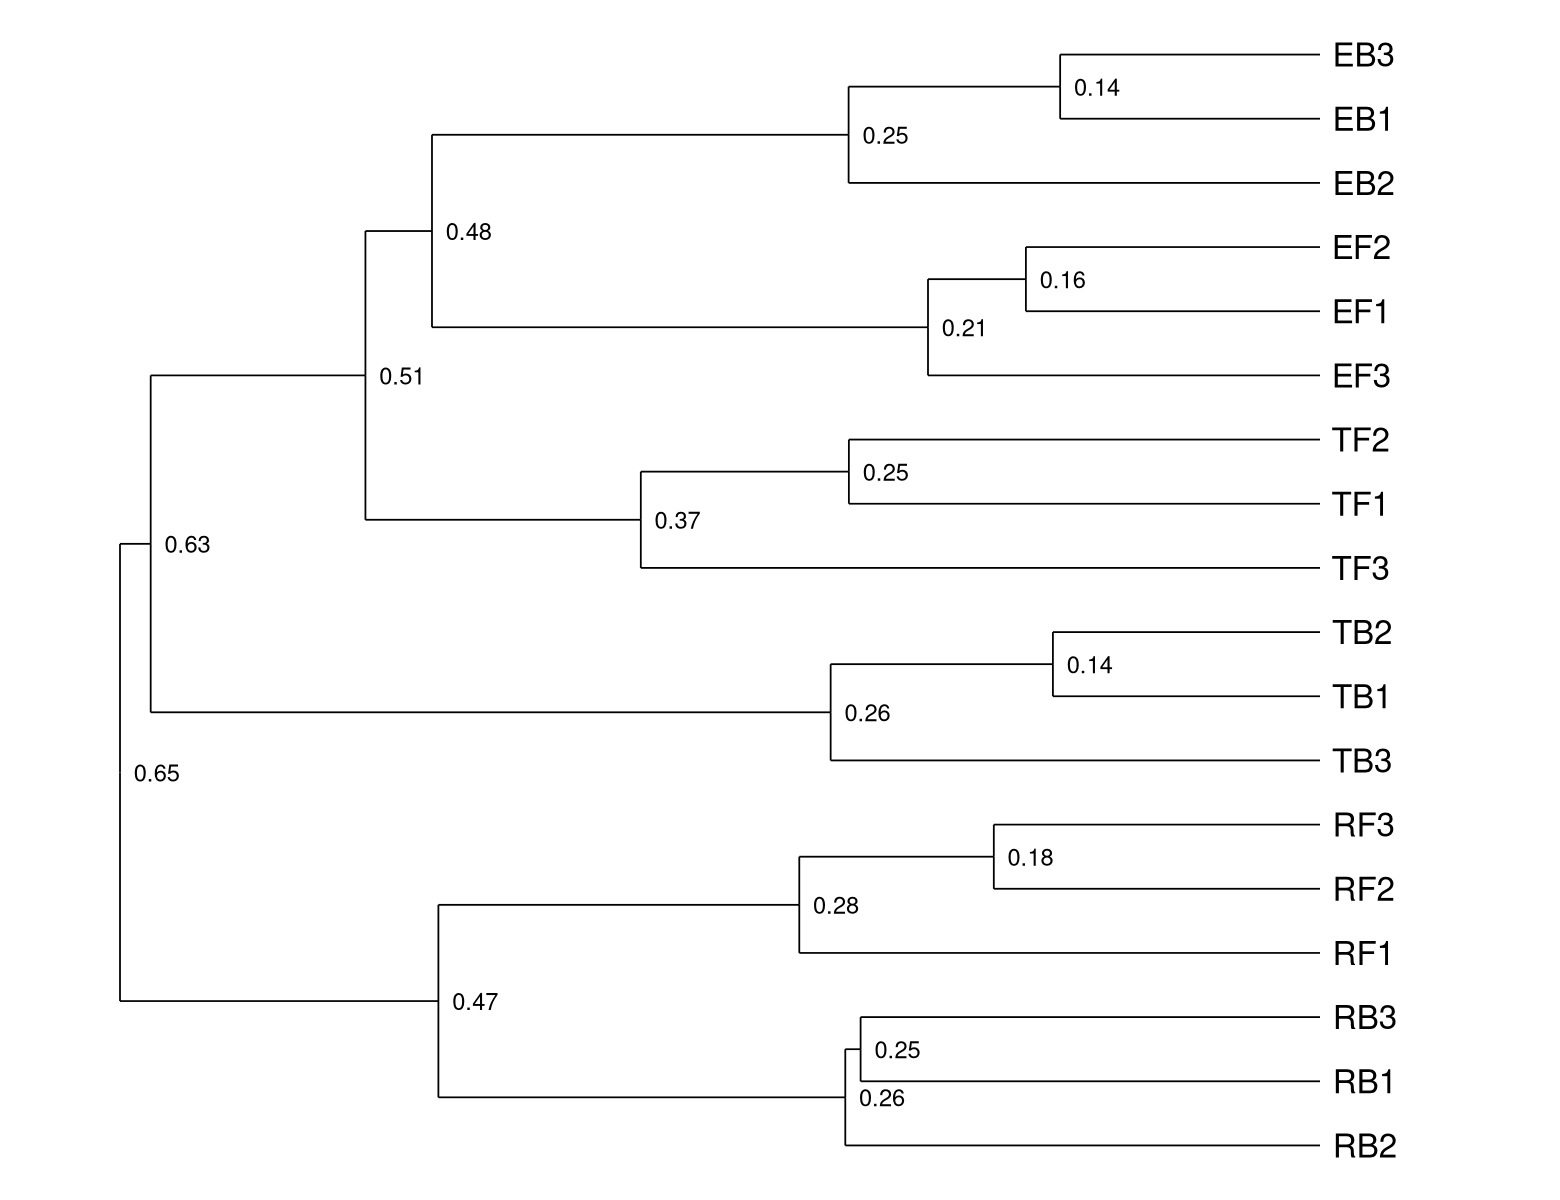

In [9]:
hc <- hclust(bray, method = "average")
dend <- dendro_data(hc, type = "rectangle")
nodes <- unique(subset(segment(dend), y == yend & y > 0, select = c(x, y)))

ggplot() +
  geom_segment(data = segment(dend), aes(x = x, y = y, xend = xend, yend = yend)) +
  geom_text(data = label(dend), aes(x = x, y = y, label = label), 
            vjust = 0.5, hjust = -0.2, size = 7) +
  geom_text(data = nodes, aes(x = x, y = y, label = round(y, 2)), 
            vjust = 0.5, hjust = -0.3, size = 5, color = "black") +
  coord_flip() +
  scale_y_reverse(expand = expansion(mult = c(0.1, 0.2))) +
  theme_void()

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”
Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”


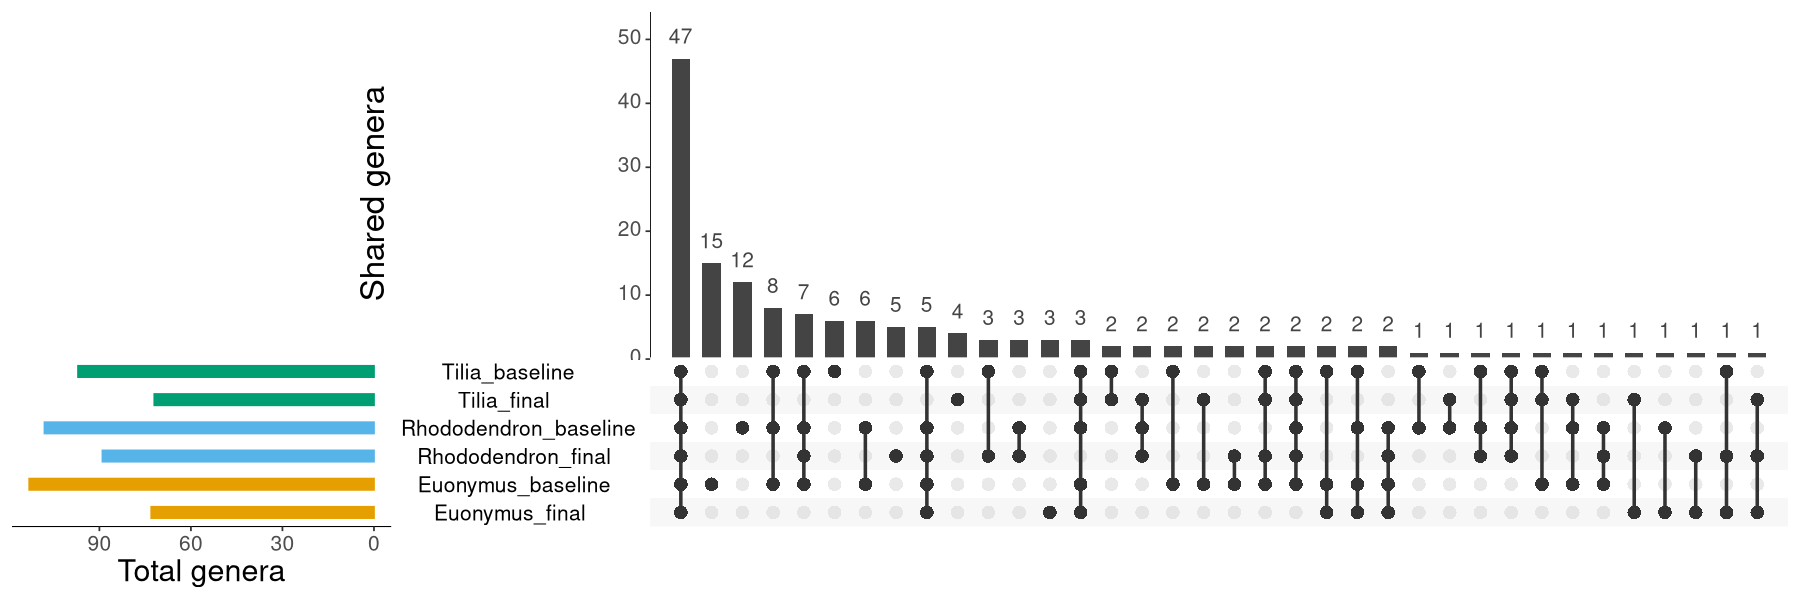

In [10]:

options(repr.plot.width = 15, repr.plot.height = 5)

# --- 1. Abundance table (taxa x samples) from the phyloseq object ---------
asvs <- as(otu_table(ps), "matrix")
if (!taxa_are_rows(ps)) asvs <- t(asvs)   # make sure rows = taxa

# --- 2. Metadata with readable group labels -------------------------------
metadata <- data.frame(sample_data(ps)) %>%
  rownames_to_column("Sample") %>%
  mutate(
    Plant_genus = recode(as.character(plant_genus),
                         E = "Euonymus", R = "Rhododendron", T = "Tilia"),
    Time_point  = recode(as.character(Time),
                         F = "final", B = "baseline"),
    group = paste(Plant_genus, Time_point, sep = "_")
  )

# --- 3. Mean abundance per group ------------------------------------------
set_order <- c(
  "Euonymus_final", "Euonymus_baseline", "Rhododendron_final",
  "Rhododendron_baseline", "Tilia_final", "Tilia_baseline")

otu_mean <- sapply(set_order, function(g) {
  samples_in_group <- metadata$Sample[metadata$group == g]
  samples_in_group <- intersect(samples_in_group, colnames(asvs))
  rowMeans(asvs[, samples_in_group, drop = FALSE])
}) %>%
  as.data.frame()

rownames(otu_mean) <- rownames(asvs)

# --- 4. Convert mean abundance to presence/absence ------------------------
upset_input <- as.data.frame((otu_mean > 0) * 1)
upset_input <- upset_input[rowSums(upset_input) > 0, ]
upset_input <- upset_input[, set_order]  # enforce column order

# --- 5. Set colors --------------------------------------------------------
genus_colors <- setNames(
  c("#E69F00", "#56B4E9", "#009E73"),
  c("Euonymus", "Rhododendron", "Tilia")
)

set_colors <- sapply(set_order, function(s) {
  genus_colors[sub("_.*", "", s)]
})

# --- 6. Plot --------------------------------------------------------------
UPSET <- UpSetR::upset(
  upset_input,
  nintersects      = 36,
  sets             = set_order,
  keep.order       = TRUE,
  order.by         = "freq",
  decreasing       = TRUE,
  sets.bar.color   = unname(set_colors),
  main.bar.color   = "#444444",
  matrix.color     = "#333333",
  point.size       = 3.5,
  line.size        = 1,
  text.scale       = c(2.4, 1.8, 2.2, 1.8, 1.8, 2),
  mainbar.y.label  = "Shared genera",   # ps taxa are genera, not ASVs
  sets.x.label     = "Total genera",
  mb.ratio         = c(0.60, 0.40)
)
UPSET

---
### References

* Anderson, M.J. (2001), A new method for non-parametric multivariate analysis of variance. Austral Ecology, 26: 32-46. https://doi.org/10.1111/j.1442-9993.2001.01070.pp.x
* Anderson, M.J. (2006), Distance-Based Tests for Homogeneity of Multivariate Dispersions. Biometrics, 62: 245-253. https://doi.org/10.1111/j.1541-0420.2005.00440.x
* Anderson, Marti & Gorley, R.N. & Clarke, K.. (2008). PERMANOVA+ for primer: Guide to software and statistical methods.
* Anderson, M.J. and Walsh, D.C.I. (2013), PERMANOVA, ANOSIM, and the Mantel test in the face of heterogeneous dispersions: What null hypothesis are you testing?. Ecological Monographs, 83: 557-574. https://doi.org/10.1890/12-2010.1
* Martinez Arbizu P (2017). _pairwiseAdonis: Pairwise Multilevel Comparison using Adonis. R package version 0.4.1, commit cb190f7668a0c82c0b0853927db239e7b9ec3e83, https://github.com/pmartinezarbizu/pairwiseAdonis.
* Oksanen J, Simpson G, Blanchet F, Kindt R, Legendre P, Minchin P, O'Hara R, Solymos P, Stevens M, Szoecs E, Wagner H, Bedward M, Bolker B, Borcard D, Carvalho G, De Caceres M, Durand S, Evangelista H, Hannigan G, Hill M, Lahti L, Martino C, Ouellette M, Ribeiro Cunha E, Smith T, Stier A, Ter Braak C, Weedon J (2026). _vegan: Community Ecology Package_. doi:10.32614/CRAN.package.vegan R package version 2.7-6 https://cran.r-project.org/package=vegan